In [1]:
import os
import rasterio
import time
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
from rasterio.warp import calculate_default_transform, reproject, Resampling
import shutil

from concurrent.futures import ThreadPoolExecutor

import time


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your CSV
df = pd.read_csv("/home/jovyan/work/training-models/nepal/Nepal_b7_2025/v5/results/history.csv")  # <-- replace with your filename

# Check columns
print(df.columns)

Index(['loss', 'sparse_categorical_accuracy', 'val_loss',
       'val_sparse_categorical_accuracy'],
      dtype='object')


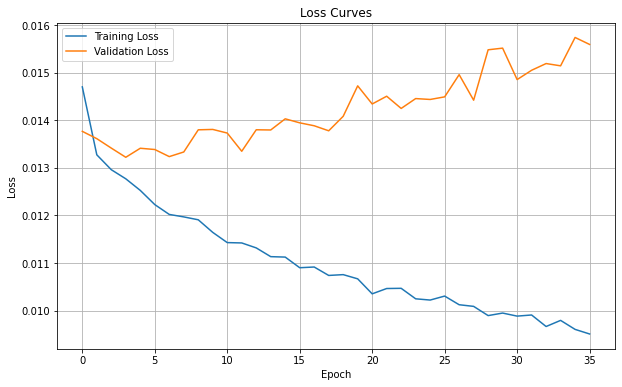

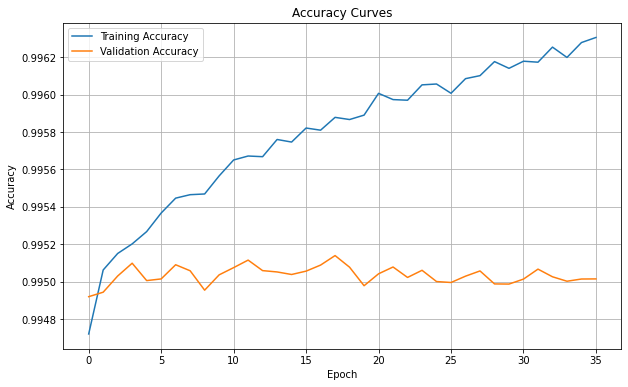

In [3]:

# ---- Plot Loss ----
plt.figure(figsize=(10, 6))
plt.plot(df["loss"], label="Training Loss")
plt.plot(df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()
plt.grid(True)
plt.show()

# ---- Plot Accuracy ----
plt.figure(figsize=(10, 6))
plt.plot(df["sparse_categorical_accuracy"], label="Training Accuracy")
plt.plot(df["val_sparse_categorical_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# function to remove NIR band

def process_file(input_path, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with rasterio.open(input_path) as src:
        if src.count >= 4:
            rgb_data = src.read([1, 2, 3])
            profile = src.profile
            profile.update(count=3)
            with rasterio.open(output_path, "w", **profile) as dst:
                dst.write(rgb_data)
            return f"Saved: {output_path}"
        else:
            return f"Skipped: {input_path}, only {src.count} bands."

def remove_nir_band(input_dir, output_dir, max_workers=4):
    start_time = time.time()
    os.makedirs(output_dir, exist_ok=True)
    files = [f for f in os.listdir(input_dir) if f.lower().endswith(".tif")]

    args = [(os.path.join(input_dir, f), os.path.join(output_dir, f))
            for f in files if not os.path.exists(os.path.join(output_dir, f))]

    if not args:
        print("All files already processed.")
        return

    results = []
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        for res in tqdm(executor.map(lambda p: process_file(*p), args),
                        total=len(args), desc="Processing rasters"):
            results.append(res)

    end_time = time.time()
    for r in results:
        print(r)
    print(f"\nFinished processing {len(args)} files with {max_workers} workers in {end_time - start_time:.2f} seconds.")

In [ ]:
#function to rename TIF to tif


def rename_to_tif(directory:str , #path to directory with .TIF or anything that is not .tif located
                 ):
    
    for filename in os.listdir(directory):
        old_path = os.path.join(directory, filename)
        
        # skip if it's already .tif
        if filename.endswith(".tif"):
            print(f"file name:{filename} ends with .tif , skipping")
            continue
        
        name, ext = os.path.splitext(filename)
        # print(name,ext)
        
        new_filename = name + ".tif"
        new_path = os.path.join(directory, new_filename)
        # print(new_path)
        
        print(f"Renaming: {old_path} -> {new_path}")
        os.rename(old_path, new_path)
    

In [ ]:
# function to reproject 


def reproject_rasters(
        lst_urls: list, #list of paths to rasters
        dest_crs: str, #destination crs, for example : 'EPSG:4326'
        local_save_path: str, #local_path to save the reprojected image
        # creds: str, #path to json file with credits to GCS
        # bucket_dest: str, #bucket where the reprojected imaegs should be stored
        # dest_path_bucket: str, #path to save the result images on GCS
        
        ):
        '''Based on this : https://hatarilabs.com/ih-en/how-to-reproject-single-and-multiple-rasters-with-python-and-rasterio-tutorial'''

        #define destination crs
        dstCrs = {'init': dest_crs}

        #iterate through list of urls to reproject
        for url in lst_urls:
              print('new loop')
              
              uniq_name=url.split('/')[-1]
              # print(uniq_name1)
            

            

#               #TODO: new name - with information about preprocess (4326 projected). TO BE CHANGED TO SOMETHING MORE GENERAL
#               lst_names=uniq_name1.split('/')[-1].split('.')
#               uniq_name=lst_names[0]+'.'+lst_names[1]+'.'+lst_names[2]+'.'+lst_names[3]+'.'+'projected_4326'+'.tif'

              print(f'unique id: {uniq_name}')
              srcRst = rasterio.open(url)
              #calculate transform array and shape of reprojected raster
              
              transform, width, height = calculate_default_transform(
                     srcRst.crs, dstCrs, srcRst.width, srcRst.height, *srcRst.bounds)
              
              #creating meta for the destination raster
              kwargs = srcRst.meta.copy()
              kwargs.update({
                     'crs': dstCrs,
                     'transform': transform,
                     'width': width,
                     'height': height
                     })
              
              #open destination raster
              print('openning new raster file for reprojected tiff')
              dstRst = rasterio.open(local_save_path+uniq_name, 'w', **kwargs)
              print(f'{local_save_path}/{uniq_name}/')
              #reproject and save raster band data
              for i in range(1, srcRst.count + 1):
                    reproject(
                           source=rasterio.band(srcRst, i),
                           destination=rasterio.band(dstRst, i),
                           #src_transform=srcRst.transform,
                           src_crs=srcRst.crs,
                           #    dst_transform=transform,
                           dst_crs=dstCrs,
                           resampling=Resampling.nearest,
                           driver='cog')
                    
              #   #close destination raster
              dstRst.close()

In [12]:
import glob
import os

def get_missing_files(input_dir, output_dir):
    # get all source files (ignore hidden files)
    src_files = [os.path.basename(f) for f in glob.glob(os.path.join(input_dir, "*")) if not os.path.basename(f).startswith(".")]

    # get all files already in destination
    dest_files = [os.path.basename(f) for f in glob.glob(os.path.join(output_dir, "*"))]

    # find missing files
    missing_files = [f for f in src_files if f not in dest_files]

    print(f"[Info] {len(missing_files)} files missing in destination, will process them.")
    return missing_files


In [15]:

#NEED TO TEST!

def preprocess_all(input_dir, output_dir, expected_crs="EPSG:4326"):


    os.makedirs(output_dir, exist_ok=True)

        # Get list of files that need processing
    files_to_process = get_missing_files(input_dir, output_dir)

    for filename in files_to_process:
        current_path = os.path.join(input_dir, filename)
        name, ext = os.path.splitext(filename)

#     for filename in os.listdir(input_dir):
#         if filename.startswith("."):
#             continue

        final_path = os.path.join(output_dir, filename)
        # ----------------------------
        # SKIP IF ALREADY PROCESSED
        # ----------------------------
        if os.path.exists(final_path):
            print(f"[Skip] {filename} already exists in output, skipping")
            continue

        current_path = os.path.join(input_dir, filename)
        name, ext = os.path.splitext(filename)

        # ---------------------------------------------------------
        # 1. FIX SUFFIX — use YOUR FUNCTION rename_to_tif()
        # ---------------------------------------------------------
        if ext != ".tif":
                print("[Suffix] Fixing suffix using rename_to_tif()")

                directory = os.path.dirname(current_path)

                # rename all files in directory using your function  
                rename_to_tif(directory)

                # Now rebuild the expected filename
                filename = os.path.splitext(filename)[0] + ".tif"
                current_path = os.path.join(directory, filename)
        else:
            print(f"[Suffix] OK → {filename}")
            current_path = current_path  # explicit

        # ---------------------------------------------------------
        # 2. REMOVE NIR IF > 3 BANDS
        # ---------------------------------------------------------
        with rasterio.open(current_path) as src:
            band_count = src.count

        if band_count > 3:
            print(f"[Bands] Removing NIR from {filename}")
            current_path = remove_nir_band(current_path, output_dir)
            filename = os.path.basename(current_path)
        else:
            print(f"[Bands] OK → 3 bands")
            current_path = current_path  # explicit

        # ---------------------------------------------------------
        # 3. CRS CHECK
        # ---------------------------------------------------------
        with rasterio.open(current_path) as src:
            crs = src.crs.to_string() if src.crs else None

        if crs != expected_crs:
            print(f"[CRS] Reprojecting {filename} → {expected_crs}")
            reproject_rasters(
                lst_urls=[current_path],
                dest_crs=expected_crs,
                local_save_path=output_dir + "/"
            )
            current_path = os.path.join(output_dir, filename)
        else:
            print(f"[CRS] OK → {expected_crs}")
            current_path = current_path  # explicit

        # ---------------------------------------------------------
        # 4. FINAL COPY
        # ---------------------------------------------------------
        
        # final copy — no else needed, always copy
        
        final_path = os.path.join(output_dir, filename)
        os.makedirs(output_dir, exist_ok=True)

        # Avoid SameFileError
        if os.path.abspath(current_path) != os.path.abspath(final_path):
            shutil.copy2(current_path, final_path)
            print(f"[Copy] {filename} saved to output")
        else:
            print(f"[Copy] Skipped (already in output)")

        current_path = final_path
        # final_path = os.path.join(output_dir, filename)
        # os.makedirs(output_dir, exist_ok=True)
        # shutil.copy2(current_path, final_path)
        # current_path = final_path
        # print(f"[Copy] {filename} saved to output")
        # # final_path = os.path.join(output_dir, filename)
        # # if os.path.abspath(current_path) != os.path.abspath(final_path):
        # #     print(f"[Copy] Copying final version of {filename} to output")
        # #     os.makedirs(output_dir, exist_ok=True)
        # #     shutil.copy2(current_path, final_path)
        # #     current_path = final_path
        # # else:
        # #     print(f"[Copy] Already in final output → {filename}")
        # #     current_path = current_path  # explicit


In [16]:
preprocess_all(input_dir ="/home/jovyan/work/imagery/Nepal/nepal_27112025/unzipped",
               output_dir = "/home/jovyan/work/imagery/Nepal/nepal_27112025/clean", 
               expected_crs="EPSG:4326")

[Info] 218 files missing in destination, will process them.
[Suffix] OK → 25APR04050936-S3DS_R1C1-200010219280_01_P001.tif
[Bands] Removing NIR from 25APR04050936-S3DS_R1C1-200010219280_01_P001.tif


NotADirectoryError: [Errno 20] Not a directory: '/home/jovyan/work/imagery/Nepal/nepal_27112025/unzipped/25APR04050936-S3DS_R1C1-200010219280_01_P001.tif'

In [17]:
import os
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import time


expected_crs = 'EPSG:4326'

############################################################
#  HELPERS
############################################################

def ensure_dir(path):
    os.makedirs(path, exist_ok=True)


############################################################
#  STEP 1 — RENAME NON-.tif FILES
############################################################

def rename_to_tif(file_path):
    """Renames file to .tif and returns new path."""
    directory, filename = os.path.split(file_path)

    if filename.lower().endswith(".tif"):
        return file_path  # nothing to change

    name, ext = os.path.splitext(filename)
    new_filename = name + ".tif"
    new_path = os.path.join(directory, new_filename)

    print(f"[Rename] {filename} → {new_filename}")
    os.rename(file_path, new_path)

    return new_path


############################################################
#  STEP 2 — REMOVE NIR BAND
############################################################

def remove_nir(input_path, output_dir):
    """If TIFF has 4+ bands, remove NIR. Returns new file path with the three first bands."""
    ensure_dir(output_dir)

    filename = os.path.basename(input_path)
    output_path = os.path.join(output_dir, filename)

    with rasterio.open(input_path) as src:
        if src.count < 4:
            print(f"[NIR-Skip] {filename}: only {src.count} bands")
            return input_path  # return the same original

        print(f"[NIR-Remove] {filename}")

        rgb_data = src.read([1, 2, 3])
        profile = src.profile
        profile.update(count=3)

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(rgb_data)

    return output_path


############################################################
#  STEP 3 — REPROJECT IF CRS IS WRONG
############################################################

def reproject_if_needed(input_path, output_dir, expected_crs):
    """Checks CRS and reprojects only if needed."""
    ensure_dir(output_dir)

    filename = os.path.basename(input_path)
    output_path = os.path.join(output_dir, filename)

    with rasterio.open(input_path) as src:
        current_crs = src.crs.to_string() if src.crs else None

        if current_crs == expected_crs:
            print(f"[CRS-OK] {filename} already in {expected_crs}")
            return input_path  # no change

        print(f"[Reproject] {filename}: {current_crs} → {expected_crs}")

        # Compute new transform
        transform, width, height = calculate_default_transform(
            src.crs, expected_crs, src.width, src.height, *src.bounds)

        kwargs = src.meta.copy()
        kwargs.update({
            "crs": expected_crs,
            "transform": transform,
            "width": width,
            "height": height
        })

        with rasterio.open(output_path, "w", **kwargs) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, i),
                    destination=rasterio.band(dst, i),
                    src_crs=src.crs,
                    dst_crs=expected_crs,
                    resampling=Resampling.nearest
                )

    return output_path


############################################################
#  MAIN PIPELINE
############################################################

def preprocess_all(input_dir, output_dir, expected_crs="EPSG:4326"):
    os.makedirs(output_dir, exist_ok=True)

    for filename in os.listdir(input_dir):
        print(f"preprocess file {filename}")
        if filename.startswith("."):
            continue

        current_path = os.path.join(input_dir, filename)
        name, ext = os.path.splitext(filename)

        # ---------------------------------------------------------
        # 1. FIX SUFFIX — use YOUR FUNCTION rename_to_tif()
        # ---------------------------------------------------------

        if ext != ".tif":
            print("[Suffix] Fixing suffix using rename_to_tif()")
            current_path = rename_to_tif(current_path)   # <--- USE YOUR FUNCTION
            filename = os.path.basename(current_path)

        # ---------------------------------------------------------
        
           # continue with steps...
        # open raster
        with rasterio.open(current_path) as src:
            band_count = src.count
            crs = src.crs.to_string() if src.crs else None

        # remove NIR if needed
        if band_count > 3:
            current_path = remove_nir(current_path, output_dir)

         # 3) CRS check
        with rasterio.open(current_path) as src:
            crs = src.crs.to_string() if src.crs else None

        if crs != expected_crs:
            reproject_rasters(
                lst_urls=[current_path],
                dest_crs=expected_crs,
                local_save_path=output_dir + "/"
            )
            current_path = os.path.join(output_dir, filename)

        # 4) If already perfect, copy
        final_path = os.path.join(output_dir, filename)
        if current_path != final_path:
            shutil.copy2(current_path, final_path)           


In [18]:
preprocess_all(input_dir ="/home/jovyan/work/imagery/Nepal/nepal_27112025/unzipped",
               output_dir = "/home/jovyan/work/imagery/Nepal/nepal_27112025/clean", 
               expected_crs="EPSG:4326")

preprocess file 25APR04050936-S3DS_R1C1-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R1C1-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R2C1-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R2C1-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R2C2-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R2C2-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R1C2-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R1C2-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R2C3-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R2C3-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R3C2-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R3C2-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R3C1-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R3C1-200010219280_01_P001.tif
preprocess file 25APR04050936-S3DS_R3C3-200010219280_01_P001.tif
[NIR-Remove] 25APR04050936-S3DS_R3C3-200010219

In [4]:
# the good  best version

In [14]:
import os
import shutil
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling


# -----------------------
# Utilities
# -----------------------
def ensure_dir(path):
    if not os.path.exists(path):
        os.makedirs(path)

def is_tif(file):
    ext = os.path.splitext(file)[1].lower()
    return ext in [".tif", ".tiff"]


# Your original functions
def remove_nir(input_path, output_dir):
    ensure_dir(output_dir)

    filename = os.path.basename(input_path)
    output_path = os.path.join(output_dir, filename)

    with rasterio.open(input_path) as src:
        if src.count < 4:
            print(f"[NIR-Skip] {filename}: only {src.count} bands")
            return input_path

        print(f"[NIR-Remove] {filename}")

        rgb_data = src.read([1, 2, 3])
        profile = src.profile
        profile.update(count=3)

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(rgb_data)

    return output_path


def reproject_if_needed(input_path, output_dir, expected_crs):
    ensure_dir(output_dir)

    filename = os.path.basename(input_path)
    output_path = os.path.join(output_dir, filename)

    with rasterio.open(input_path) as src:
        current_crs = src.crs.to_string() if src.crs else None

        if current_crs == expected_crs:
            print(f"[CRS-OK] {filename} already in {expected_crs}")
            return input_path

        print(f"[Reproject] {filename}: {current_crs} → {expected_crs}")

        transform, width, height = calculate_default_transform(
            src.crs, expected_crs, src.width, src.height, *src.bounds
        )

        kwargs = src.meta.copy()
        kwargs.update({
            "crs": expected_crs,
            "transform": transform,
            "width": width,
            "height": height,
        })

        with rasterio.open(output_path, "w", **kwargs) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, i),
                    destination=rasterio.band(dst, i),
                    src_crs=src.crs,
                    dst_crs=expected_crs,
                    resampling=Resampling.nearest,
                )

    return output_path



# -----------------------
#   MAIN PIPELINE
# -----------------------

def process_tifs(source_dir, dest_dir, expected_crs="EPSG:4326"):
    ensure_dir(dest_dir)

    source_files = [f for f in os.listdir(source_dir) if is_tif(f)]
    dest_files = [f.lower() for f in os.listdir(dest_dir) if is_tif(f)]

    print(f"Found {len(source_files)} TIFFs in source.")
    print(f"{len(dest_files)} TIFFs already exist in destination.")

    for filename in source_files:
        src_path = os.path.join(source_dir, filename)

        # Normalize output name (make sure extension becomes .tif)
        out_name = os.path.splitext(filename)[0] + ".tif"

        # If output already exists → skip completely
        if out_name.lower() in dest_files:
            print(f"\n[Skip] {out_name} already processed.")
            continue

        initial_copy_path = os.path.join(dest_dir, out_name)

        # Step 1 — COPY original file
        print(f"\n[Copy] {filename} → {out_name}")
        shutil.copy(src_path, initial_copy_path)

        # Step 2 — Remove NIR if needed
        
        nir_fixed_path = remove_nir(initial_copy_path, dest_dir)

        # Step 3 — Reproject if needed
        final_path = reproject_if_needed(nir_fixed_path, dest_dir, expected_crs)


    # Final check
    final_output_files = [f for f in os.listdir(dest_dir) if is_tif(f)]

    print("\n✔ Processing complete.")
    print(f"Source TIFF count: {len(source_files)}")
    print(f"Dest TIFF count:   {len(final_output_files)}")

    return True


In [15]:
process_tifs(source_dir="/home/jovyan/work/imagery/Nepal/merged_04122025/imgs_copied"
             , dest_dir="/home/jovyan/work/imagery/Nepal/merged_04122025/qaim"
             , expected_crs="EPSG:4326")

Found 397 TIFFs in source.
0 TIFFs already exist in destination.

[Copy] 19JAN16050540-S3DS_R1C1-200010623526_01_P001.tif → 19JAN16050540-S3DS_R1C1-200010623526_01_P001.tif
[NIR-Skip] 19JAN16050540-S3DS_R1C1-200010623526_01_P001.tif: only 3 bands
[CRS-OK] 19JAN16050540-S3DS_R1C1-200010623526_01_P001.tif already in EPSG:4326

[Copy] 19JAN16050540-S3DS_R1C2-200010623526_01_P001.tif → 19JAN16050540-S3DS_R1C2-200010623526_01_P001.tif
[NIR-Skip] 19JAN16050540-S3DS_R1C2-200010623526_01_P001.tif: only 3 bands
[CRS-OK] 19JAN16050540-S3DS_R1C2-200010623526_01_P001.tif already in EPSG:4326

[Copy] 19JAN16050540-S3DS_R2C1-200010623526_01_P001.tif → 19JAN16050540-S3DS_R2C1-200010623526_01_P001.tif
[NIR-Skip] 19JAN16050540-S3DS_R2C1-200010623526_01_P001.tif: only 3 bands
[CRS-OK] 19JAN16050540-S3DS_R2C1-200010623526_01_P001.tif already in EPSG:4326

[Copy] 19JAN16050540-S3DS_R2C2-200010623526_01_P001.tif → 19JAN16050540-S3DS_R2C2-200010623526_01_P001.tif
[NIR-Skip] 19JAN16050540-S3DS_R2C2-200010623

RasterioIOError: /home/jovyan/work/imagery/Nepal/merged_04122025/qaim/22MAR25051033-S3DS_R3C1-200010642978_01_P001.tif: TIFFReadDirectory:Failed to read directory at offset 1075713362

In [1]:
import glob

In [2]:
import glob
len(glob.glob("/home/jovyan/work/imagery/afghanistan/train_validation/imgs/*"))

165